<a href="https://colab.research.google.com/github/Priyankaewp/schools-project/blob/main/DataCleaningDay5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [43]:
# importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Load the dataset
df = pd.read_csv("Messy_data.csv")

In [6]:
# Inspecting the data
# Data inspecting functions ----> df.info(), df.describe(), df.shape
df.head()

,OrderID,CustomerName,City,Product,Quantity,UnitPrice,OrderDate,OrderStatus,CustomerAge
0,10001,Nikhil Jain,Mumbai,Laptop,3.0,50790.72,2026-01-18,Completed,61.0
1,10002,Simran Kaur,delhi,Monitor,1.0,10307.27,2026-01-28,Pending,50.0
2,10003,Zoya Ali,Delhi,Headphones,5.0,2439.64,2026-02-27,Delivered,35.0
3,10004,Priya Bansal,Delhi,Tablet,4.0,20945.65,02/03/2026,Pending,66.0
4,10005,NaN,Mumbai,Phone,4.0,15822.27,2026-02-14,Delivered,34.0


In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   OrderID       185 non-null    int64 
 1   CustomerName  183 non-null    object
 2   City          183 non-null    object
 3   Product       185 non-null    object
 4   Quantity      183 non-null    object
 5   UnitPrice     183 non-null    object
 6   OrderDate     183 non-null    object
 7   OrderStatus   183 non-null    object
 8   CustomerAge   183 non-null    object
dtypes: int64(1), object(8)
memory usage: 13.1+ KB
None


In [8]:
print(df.shape)

(185, 9)


In [9]:
# Print rows and columns
print("Rows:" , df.shape[0])
print("Columns:", df.shape[1])


Rows: 185
Columns: 9


In [10]:
print(df.describe())

            OrderID
count    185.000000
mean   10090.135135
std       52.229719
min    10001.000000
25%    10045.000000
50%    10090.000000
75%    10135.000000
max    10180.000000


In [12]:
# get the data of all columns
df.describe(include="all")

,OrderID,CustomerName,City,Product,Quantity,UnitPrice,OrderDate,OrderStatus,CustomerAge
count,185.000000,183,183,185,183,183,183,183,183
unique,NaN,33,12,10,9,178,83,8,54
top,NaN,Simran Kaur,Bengaluru,Phone,1.0,5768.41,2026-03-31,Delivered,24.0
freq,NaN,12,33,34,42,2,7,42,8
mean,10090.135135,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,52.229719,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,10001.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,10045.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,10090.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,10135.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# missing values
print(df.isnull().sum())


OrderID         0
CustomerName    2
City            2
Product         0
Quantity        2
UnitPrice       2
OrderDate       2
OrderStatus     2
CustomerAge     2
dtype: int64


In [14]:
# check for the duplicate records
print(df.duplicated().sum())

5


In [15]:
# Removing the duplicate records
df= df.drop_duplicates()

In [16]:
print(df.duplicated().sum())

0


In [18]:
df.shape

(180, 9)

In [20]:
# Clean extra spaces and standardize the text
text_columns = ["CustomerName", "City", "Product", "OrderStatus"]
df["CustomerName"] = df["CustomerName"].str.title()
df["City"] = df["City"].str.title()
df["Product"] = df["Product"].str.title()
df["OrderStatus"] = df["OrderStatus"].str.title()

In [21]:
#  convert datatype
# remove extra spaces

for col in text_columns:
  df[col]= df[col].astype("string").str.strip()

In [22]:
# Before checking outlier for Unit price, check the datatype of UnitPrice, it is Object.
# It will through an error.
# Hence convert object datatype to numeric datatype.
# convert the "UnitPrice" into numeric datatype

df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors= "coerce")


In [23]:
# Outliers for "UnitPrice"
Q1 = df["UnitPrice"].quantile(0.25)
Q3 = df["UnitPrice"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [24]:
df["UniPrice"] = df["UnitPrice"].clip(lower_bound,upper_bound)

In [26]:
# convert the "quantity" into numeric datatype
df["Quantity"] = pd.to_numeric(df["Quantity"], errors= "coerce")

In [27]:
# create a new column - i.e., total amount
df["Total_Amount"]= df["Quantity"]*df["UnitPrice"]

In [28]:
print(df['Total_Amount'].head())


0    152372.16
1     10307.27
2     12198.20
3     83782.60
4     63289.08
Name: Total_Amount, dtype: float64


In [38]:
# Missing Values
df["CustomerName"] = df["CustomerName"].fillna("Unknown")
df["City"] = df["City"].fillna("Unknown")
df["OrderStatus"] = df["OrderStatus"].fillna("Unknown")
df["Quantity"]= df["Quantity"].fillna(df["Quantity"].median())

In [31]:
# Handling Date inconsistencies
df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce")

In [36]:
# convert the "CustomerAge" into numeric datatype

df["CustomerAge"] = pd.to_numeric(df["CustomerAge"], errors= "coerce")

# Outliers for "CustomerAge"
Q1 = df["CustomerAge"].quantile(0.25)
Q3 = df["CustomerAge"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [37]:
df["CustomerAge"] = df["CustomerAge"].clip(lower_bound,upper_bound)

In [40]:
# convert the "Quantity" into numeric datatype

df["Quantity"] = pd.to_numeric(df["Quantity"], errors= "coerce")

# Outliers for "Quantity"
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [41]:
df["Quantity"] = df["Quantity"].clip(lower_bound,upper_bound)

count    176.000000
mean      44.571733
std       15.936277
min        3.000000
25%       31.000000
50%       45.000000
75%       57.250000
max       96.625000
Name: CustomerAge, dtype: float64


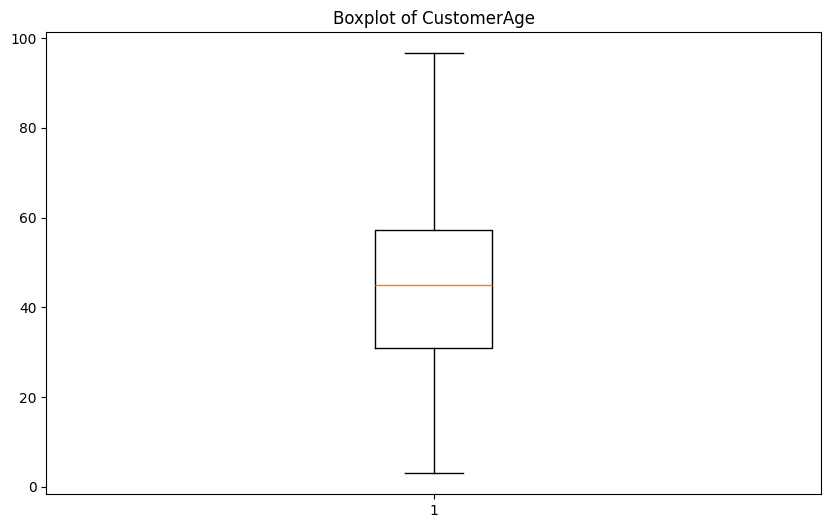

In [44]:
print(df['CustomerAge'].describe())
plt.figure(figsize = (10,6))
plt.boxplot(df['CustomerAge'].dropna())
plt.title("Boxplot of CustomerAge")
plt.show()

In [45]:
print(IQR)

2.0


count    180.000000
mean       2.911111
std        1.473372
min       -1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        7.000000
Name: Quantity, dtype: float64


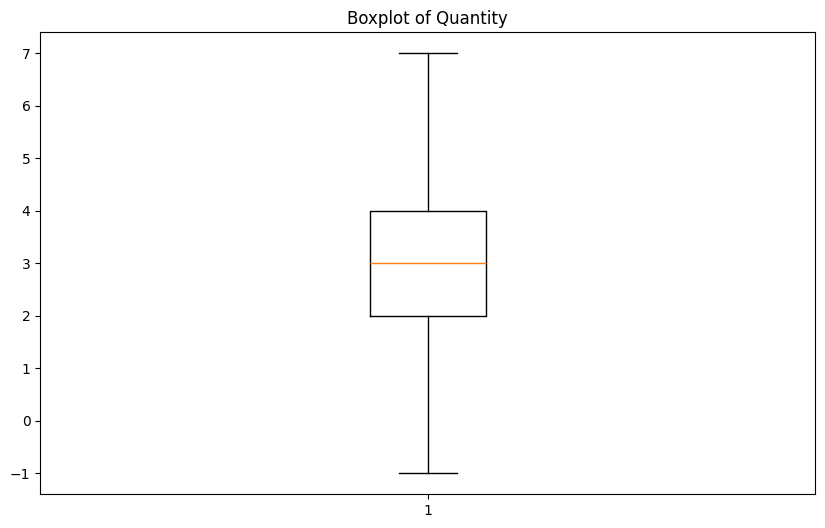

In [46]:
print(df['Quantity'].describe())
plt.figure(figsize = (10,6))
plt.boxplot(df['Quantity'].dropna())
plt.title("Boxplot of Quantity")
plt.show()

In [47]:
print(IQR)

2.0


count       176.000000
mean      19832.414830
std       75865.387087
min           0.010000
25%        2451.085000
50%       10858.250000
75%       19484.397500
max      999999.000000
Name: UnitPrice, dtype: float64


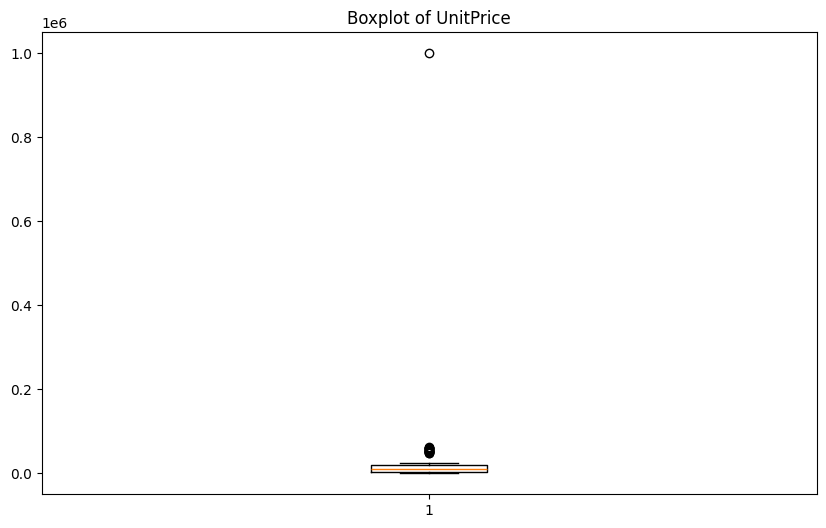

In [48]:
print(df['UnitPrice'].describe())
plt.figure(figsize = (10,6))
plt.boxplot(df['UnitPrice'].dropna())
plt.title("Boxplot of UnitPrice")
plt.show()

In [49]:
# display outliers - "UnitPrice"
outlier1 = df[(df['UnitPrice']<lower) | (df['UnitPrice']>upper)]
print(outlier1)

# display outliers - "Quantity"
outlier2 = df[(df['Quantity']<lower) | (df['Quantity']>upper)]
print(outlier2)

# display outliers - "CustomerAge"
outlier3 = df[(df['CustomerAge']<lower) | (df['CustomerAge']>upper)]
print(outlier3)

     OrderID  CustomerName     City     Product  Quantity  UnitPrice  \
0      10001   Nikhil Jain   Mumbai      Laptop       3.0   50790.72   
1      10002   Simran Kaur    Delhi     Monitor       1.0   10307.27   
2      10003      Zoya Ali    Delhi  Headphones       5.0    2439.64   
3      10004  Priya Bansal    Delhi      Tablet       4.0   20945.65   
4      10005       Unknown   Mumbai       Phone       4.0   15822.27   
..       ...           ...      ...         ...       ...        ...   
175    10176   Nikhil Jain    Delhi       Mouse       1.0     723.30   
176    10177   Tara Kapoor    Delhi      Tablet       2.0   22437.72   
177    10178   Simran Kaur    Delhi       Phone       5.0   16461.72   
178    10179     Sana Khan  Chennai       Mouse       3.0     866.44   
179    10180   Mohit Yadav    Delhi      Tablet       2.0   23679.28   

     OrderDate OrderStatus  CustomerAge     UniPrice  Total_Amount  
0   2026-01-18   Completed         61.0  45034.36625     152372.16

In [50]:
from google.colab import files
df.to_csv("cleaned_sales_dataset.csv", index= False)
files.download("cleaned_sales_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Steps:**
1. Upload the required file to collab
2. importing the necessary libraries.
3. link the excel/csv file to the dataframe df
4. Inspecting the data,
       Data inspecting functions ----> df.info(), df.describe(), df.shape, df.isnull().sum(),
5. Check for missing values
6. check for duplicates records and Removing the duplicates.
7. Clean extra spaces and standardize the text
8. convert datatype and remove extra spaces
9. Outliers for "UnitPrice", "CustomerAge", "Quantity".
10. create a new column
11. Handlimg missing values
12. Handling Date inconsistencies
13. Boxplot of outliers - "UnitPrice" , "Quantity", "CustomerAge"
14. display outliers - "UnitPrice" , "Quantity", "CustomerAge"
15. Download the cleaned file as " cleaned_sales_dataset.csv."